# Détection d'objets avec un modèle pré-entraîné

Dans cette démo, nous appliquons un détecteur d'objets pré-entraîné de torchvision, Faster R-CNN, à quelques images. Pour chaque objet détecté, il rend une boîte englobante (*bounding box*), une étiquette et un score. Nous allons :

1. charger le modèle et l'appliquer aux images, puis afficher ses boîtes et ses scores ;
2. calculer l'intersection sur union (IoU) entre deux boîtes, et comparer les détections à une vérité terrain ;
3. appliquer nous-mêmes la suppression des non-maxima (NMS), que le modèle fait d'habitude en interne.

Cette démo n'a pas besoin de carte graphique : sur CPU, elle s'exécute en quelques minutes.

## Images

PyTorch et torchvision sont préinstallés sur Colab et dans le Codespace. Les images sont celles des exemples de la documentation de torchvision (dépôt [pytorch/vision](https://github.com/pytorch/vision/tree/v0.24.0/gallery/assets), version 0.24.0) :

- des piétons, tirés de la base [Penn-Fudan](https://www.cis.upenn.edu/~jshi/ped_html/), avec leur masque annoté, qui nous servira de vérité terrain ;
- un skateur, un chien et une poterie.

La cellule suivante les télécharge dans le dossier `images`, puis les lit en tenseurs d'entiers de forme `(canaux, hauteur, largeur)`.

In [1]:
import urllib.request
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import torch
from matplotlib.patches import Rectangle
from torchvision.io import ImageReadMode, decode_image
from torchvision.models.detection import (
  FasterRCNN_ResNet50_FPN_V2_Weights,
  fasterrcnn_resnet50_fpn_v2,
)
from torchvision.ops import batched_nms, box_iou, masks_to_boxes, nms

url_base = "https://raw.githubusercontent.com/pytorch/vision/v0.24.0/gallery/assets"
noms = ["FudanPed00054.png", "person1.jpg", "dog1.jpg", "pottery.jpg"]
nom_masque = "FudanPed00054_mask.png"

dossier_images = Path("images")
dossier_images.mkdir(exist_ok=True)
for nom in [*noms, nom_masque]:
  if not (dossier_images / nom).exists():
    urllib.request.urlretrieve(f"{url_base}/{nom}", dossier_images / nom)

images = [decode_image(dossier_images / nom, mode=ImageReadMode.RGB) for nom in noms]
for nom, image in zip(noms, images):
  print(f"{nom} : {tuple(image.shape)}, {image.dtype}")

FudanPed00054.png : (3, 498, 533), torch.uint8
person1.jpg : (3, 640, 480), torch.uint8
dog1.jpg : (3, 500, 500), torch.uint8
pottery.jpg : (3, 1200, 900), torch.uint8


## Le modèle

Faster R-CNN est un détecteur à **deux étapes** :

- un *backbone* (ici ResNet-50 avec un FPN, *Feature Pyramid Network*) calcule des cartes de caractéristiques à plusieurs échelles ;
- première étape : le RPN (*Region Proposal Network*) propose des régions candidates, susceptibles de contenir un objet ;
- seconde étape : la tête ROI (*Region of Interest*) donne la classe de chaque région et affine sa boîte.

Les poids `DEFAULT` sont ceux d'un entraînement sur [COCO](https://cocodataset.org/), un jeu de 80 classes d'objets courants. `poids.transforms()` convertit une image en flottants dans $[0, 1]$ : le modèle la redimensionne et la normalise lui-même. `poids.meta["categories"]` donne le nom de chaque classe (91 indices : le fond `__background__`, les 80 classes, et des `N/A` pour les numéros que COCO a prévus sans les annoter).

Le premier chargement télécharge les poids (167 Mo).

In [2]:
poids = FasterRCNN_ResNet50_FPN_V2_Weights.DEFAULT  # pré-entraîné sur COCO
modele = fasterrcnn_resnet50_fpn_v2(weights=poids).eval()
pretraitement = poids.transforms()
categories = poids.meta["categories"]

nb_parametres = sum(parametre.numel() for parametre in modele.parameters())
nb_classes = len([nom for nom in categories if nom not in ("__background__", "N/A")])
print(f"{nb_parametres / 1e6:.0f} millions de paramètres, {nb_classes} classes")
print(f"Première étape : {type(modele.rpn).__name__}")
print(f"Seconde étape : {type(modele.roi_heads).__name__}")
print(f"mAP sur COCO val2017 : {poids.meta['_metrics']['COCO-val2017']['box_map']}")

44 millions de paramètres, 80 classes
Première étape : RegionProposalNetwork
Seconde étape : RoIHeads
mAP sur COCO val2017 : 46.7


## Inférence

Le modèle prend une liste d'images, de tailles quelconques, et rend un dictionnaire par image :

- `boxes` : les boîtes, de forme `(N, 4)`, au format `x1 y1 x2 y2` (coins haut gauche et bas droit, en pixels de l'image d'origine) ;
- `labels` : l'indice de la classe de chaque boîte ;
- `scores` : la confiance du modèle, par ordre décroissant.

Il rend au plus 100 détections par image, de score supérieur à 0,05.

In [3]:
with torch.no_grad():
  sorties = modele([pretraitement(image) for image in images])

for nom, sortie in zip(noms, sorties):
  print(f"{nom} : {len(sortie['boxes'])} détections")
  for boite, etiquette, score in zip(
    sortie["boxes"][:5], sortie["labels"][:5], sortie["scores"][:5]
  ):
    print(
      f"  {categories[etiquette]:<14} {score:.3f}  {[round(x) for x in boite.tolist()]}"
    )

FudanPed00054.png : 37 détections
  person         1.000  [363, 115, 438, 332]
  person         1.000  [287, 113, 362, 334]
  person         0.999  [95, 133, 184, 422]
  person         0.998  [490, 120, 519, 196]
  sports ball    0.957  [33, 163, 47, 178]
person1.jpg : 9 détections
  person         0.999  [125, 178, 322, 569]
  skateboard     0.998  [159, 549, 343, 584]
  baseball bat   0.853  [10, 310, 308, 478]
  baseball bat   0.215  [106, 223, 442, 415]
  bowl           0.179  [244, 345, 270, 363]
dog1.jpg : 4 détections
  dog            0.998  [219, 171, 407, 389]
  person         0.412  [344, 163, 359, 224]
  person         0.249  [300, 167, 316, 233]
  person         0.098  [302, 200, 313, 233]
pottery.jpg : 4 détections
  fire hydrant   0.770  [103, 208, 802, 980]
  teddy bear     0.552  [116, 224, 799, 961]
  elephant       0.209  [112, 242, 797, 970]
  vase           0.060  [102, 233, 806, 967]


## Affichage des boîtes

Les détections de faible score sont souvent fausses : avant d'afficher, on ne garde que celles dont le score dépasse un seuil, ici 0,5. Chaque boîte est étiquetée par sa classe et son score.

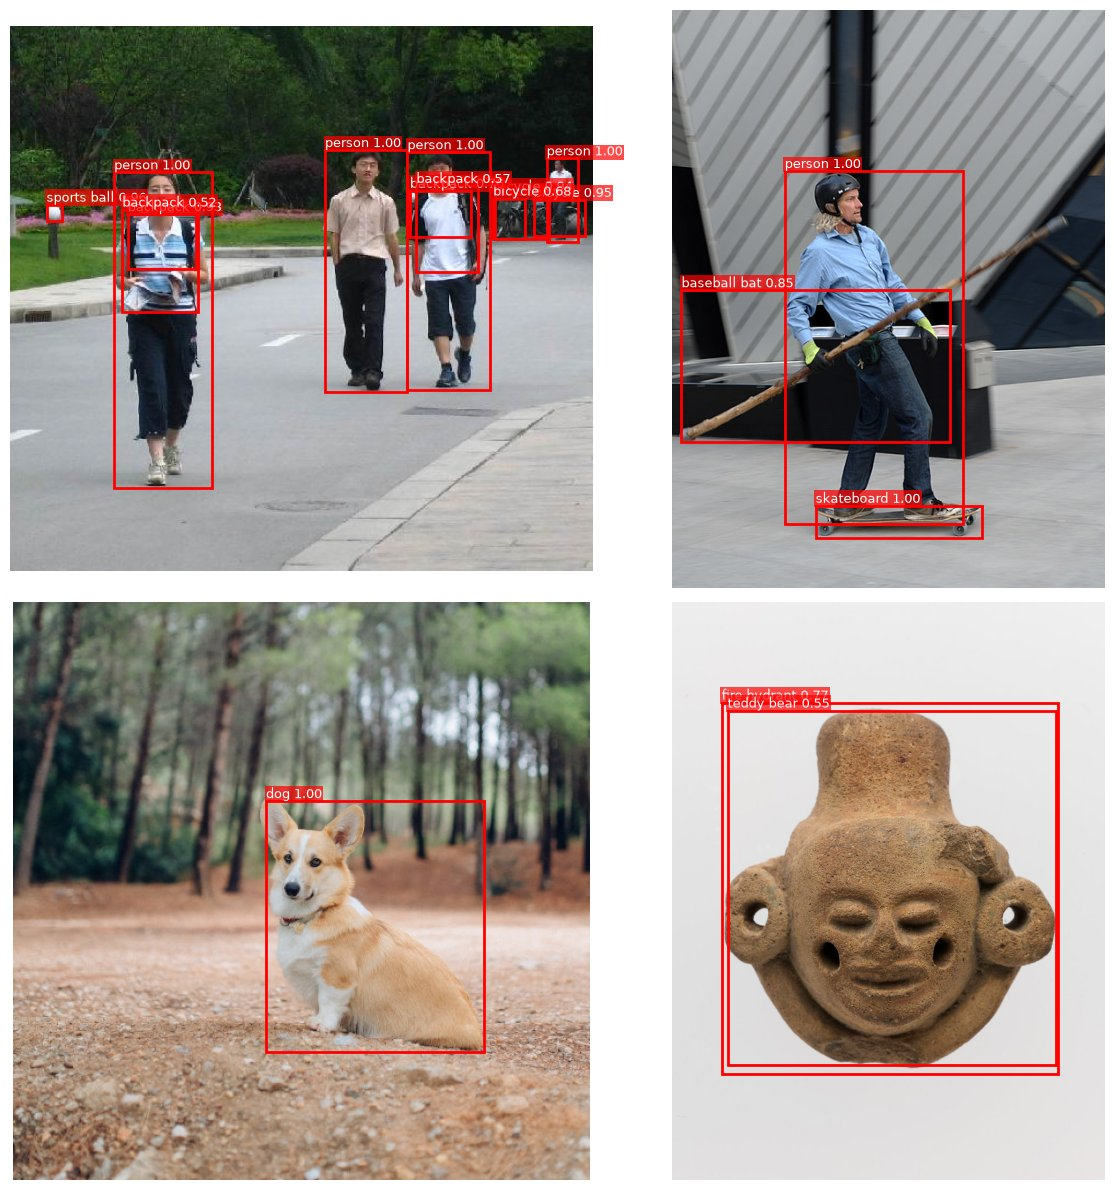

In [4]:
seuil_score = 0.5


def affiche_image(ax, image):
  ax.imshow(image.permute(1, 2, 0))  # (hauteur, largeur, canaux) pour matplotlib
  ax.axis("off")


def dessine_boites(ax, boites, textes=None, couleur="red", epaisseur=2):
  """Dessine les boîtes x1 y1 x2 y2, chacune avec son texte au-dessus."""
  for i, (x1, y1, x2, y2) in enumerate(boites.tolist()):
    ax.add_patch(
      Rectangle(
        (x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=couleur, linewidth=epaisseur
      )
    )
    if textes is not None:
      ax.text(
        x1,
        y1,
        textes[i],
        color="white",
        fontsize=9,
        va="bottom",
        bbox={"facecolor": couleur, "alpha": 0.7, "pad": 1, "edgecolor": "none"},
      )


def textes_detection(sortie, garde):
  return [
    f"{categories[etiquette]} {score:.2f}"
    for etiquette, score in zip(sortie["labels"][garde], sortie["scores"][garde])
  ]


fig, axes = plt.subplots(2, 2, figsize=(12, 12))
for ax, image, sortie in zip(axes.flat, images, sorties):
  garde = sortie["scores"] >= seuil_score
  affiche_image(ax, image)
  dessine_boites(ax, sortie["boxes"][garde], textes_detection(sortie, garde))
plt.tight_layout()
plt.show()

- Les piétons, leurs sacs à dos, les vélos du fond, le skateur, sa planche et le chien sont bien localisés et bien classés.
- Le globe blanc du lampadaire, à gauche des piétons, devient un ballon (*sports ball*), avec un score de 0,96 : un score élevé ne garantit pas une détection juste.
- Le bâton du skateur devient une batte de baseball (*baseball bat*), et la poterie une bouche d'incendie ou un ours en peluche : le détecteur ne connaît que les 80 classes de COCO et répond toujours par l'une d'elles. Pour d'autres classes, on l'affine sur ses propres images en remplaçant sa tête (`FastRCNNPredictor`), ou on prend un détecteur à vocabulaire ouvert (Grounding DINO, OWLv2, YOLO-World), qui reçoit ses classes en texte.

Le seuil de score règle le compromis entre précision et rappel : bas, il garde des objets peu visibles mais aussi de fausses détections, comme les « personnes » de score 0,41 et 0,25 que le modèle voit dans les arbres derrière le chien ; haut, il perd de vrais objets.

In [5]:
for seuil in (0.05, 0.3, 0.5, 0.9):
  effectifs = [int((sortie["scores"] >= seuil).sum()) for sortie in sorties]
  print(f"Score >= {seuil} : {dict(zip(noms, effectifs))}")

Score >= 0.05 : {'FudanPed00054.png': 37, 'person1.jpg': 9, 'dog1.jpg': 4, 'pottery.jpg': 4}
Score >= 0.3 : {'FudanPed00054.png': 17, 'person1.jpg': 3, 'dog1.jpg': 2, 'pottery.jpg': 2}
Score >= 0.5 : {'FudanPed00054.png': 12, 'person1.jpg': 3, 'dog1.jpg': 1, 'pottery.jpg': 2}
Score >= 0.9 : {'FudanPed00054.png': 8, 'person1.jpg': 2, 'dog1.jpg': 1, 'pottery.jpg': 0}


## Intersection sur union (IoU)

L'IoU mesure le recouvrement entre deux boîtes :

$$\text{IoU} = \frac{\text{aire de l'intersection}}{\text{aire de l'union}} \in [0, 1]$$

Une détection est jugée correcte si son IoU avec une boîte de la vérité terrain dépasse un seuil, souvent 0,5.

Pour l'image des piétons, la base Penn-Fudan fournit un masque : chaque pixel vaut 0 sur le fond, et $i$ sur le $i$-ième piéton annoté. `masks_to_boxes` en déduit la boîte englobante de chaque piéton : c'est notre vérité terrain.

3 piétons annotés, 4 personnes détectées


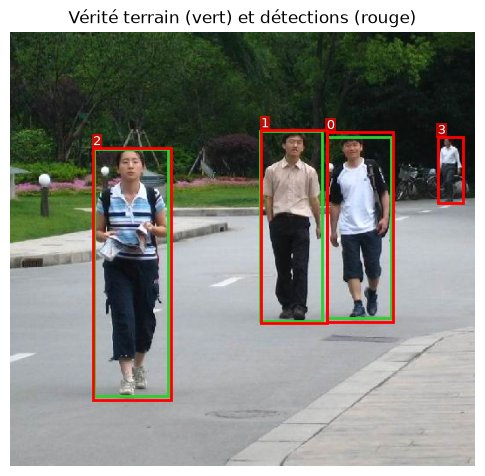

In [6]:
masque = decode_image(dossier_images / nom_masque)[0]  # (hauteur, largeur)
ids_pietons = masque.unique()[1:]  # sans le fond, 0
boites_verite = masks_to_boxes(masque == ids_pietons[:, None, None])

pietons = sorties[0]
est_personne = pietons["labels"] == categories.index("person")
garde = (pietons["scores"] >= seuil_score) & est_personne
boites_personnes = pietons["boxes"][garde]
print(
  f"{len(boites_verite)} piétons annotés, {len(boites_personnes)} personnes détectées"
)

fig, ax = plt.subplots(figsize=(6, 6))
affiche_image(ax, images[0])
dessine_boites(ax, boites_verite, couleur="limegreen")
dessine_boites(ax, boites_personnes, [f"{i}" for i in range(len(boites_personnes))])
ax.set_title("Vérité terrain (vert) et détections (rouge)")
plt.show()

Calculons l'IoU à la main pour deux boîtes : l'intersection est le rectangle compris entre le plus grand des coins haut gauche et le plus petit des coins bas droit (vide si ces coins se croisent), et l'aire de l'union est la somme des deux aires moins celle de l'intersection.

In [7]:
def iou(boite_a, boite_b):
  """IoU de deux boîtes x1 y1 x2 y2."""
  x1, y1 = max(boite_a[0], boite_b[0]), max(boite_a[1], boite_b[1])
  x2, y2 = min(boite_a[2], boite_b[2]), min(boite_a[3], boite_b[3])
  intersection = max(0, x2 - x1) * max(0, y2 - y1)
  aire_a = (boite_a[2] - boite_a[0]) * (boite_a[3] - boite_a[1])
  aire_b = (boite_b[2] - boite_b[0]) * (boite_b[3] - boite_b[1])
  return intersection / (aire_a + aire_b - intersection)


verite = boites_verite[0].tolist()
for i, boite in enumerate(boites_personnes.tolist()):
  print(f"IoU(vérité 0, détection {i}) = {iou(verite, boite):.3f}")

IoU(vérité 0, détection 0) = 0.000
IoU(vérité 0, détection 1) = 0.000
IoU(vérité 0, détection 2) = 0.933
IoU(vérité 0, détection 3) = 0.000


`box_iou` de torchvision calcule d'un coup la matrice des IoU entre deux ensembles de boîtes : une ligne par détection, une colonne par boîte de la vérité terrain. Chaque détection est associée à la boîte de vérité terrain qu'elle recouvre le plus, et jugée correcte si cette IoU dépasse 0,5.

In [8]:
ious = box_iou(boites_personnes, boites_verite)
print(ious.numpy().round(3))

meilleures_iou, meilleures_verites = ious.max(dim=1)
for i, (meilleure_iou, verite) in enumerate(zip(meilleures_iou, meilleures_verites)):
  verdict = f"correcte (vérité {verite})" if meilleure_iou > 0.5 else "fausse"
  print(f"Détection {i} : meilleure IoU {meilleure_iou:.3f} → {verdict}")

[[0.    0.    0.927]
 [0.    0.901 0.   ]
 [0.933 0.    0.   ]
 [0.    0.    0.   ]]
Détection 0 : meilleure IoU 0.927 → correcte (vérité 2)
Détection 1 : meilleure IoU 0.901 → correcte (vérité 1)
Détection 2 : meilleure IoU 0.933 → correcte (vérité 0)
Détection 3 : meilleure IoU 0.000 → fausse


Les trois piétons annotés sont détectés avec une IoU proche de 0,9. L'homme du fond est bien une personne, mais la base ne l'a pas annoté : l'évaluation compte sa détection comme fausse. Une mesure comme la mAP ne vaut que ce que vaut l'annotation.

## Suppression des non-maxima (NMS)

Le détecteur produit souvent plusieurs boîtes pour un même objet. Sa tête ROI applique une NMS par classe avant de rendre ses détections, avec un seuil d'IoU de 0,5 (`modele.roi_heads.nms_thresh`). Pour voir les boîtes en double, désactivons-la : avec un seuil d'IoU de 1, aucune boîte n'est supprimée, puisqu'une IoU ne dépasse jamais 1. On relève aussi la limite de 100 détections par image (`detections_per_img`), puis on rétablit les deux réglages.

In [9]:
reglages = modele.roi_heads.nms_thresh, modele.roi_heads.detections_per_img
print(f"Seuil de la NMS du modèle : {reglages[0]}")
modele.roi_heads.nms_thresh, modele.roi_heads.detections_per_img = 1.0, 1000
with torch.no_grad():
  brut = modele([pretraitement(images[0])])[0]
modele.roi_heads.nms_thresh, modele.roi_heads.detections_per_img = reglages

garde = brut["scores"] >= seuil_score
boites_brutes, scores_bruts, etiquettes_brutes = (
  brut["boxes"][garde],
  brut["scores"][garde],
  brut["labels"][garde],
)
print(f"Sans NMS : {len(boites_brutes)} boîtes de score >= {seuil_score}")
print(Counter(categories[etiquette] for etiquette in etiquettes_brutes).most_common())

Seuil de la NMS du modèle : 0.5
Sans NMS : 149 boîtes de score >= 0.5
[('person', 65), ('bicycle', 48), ('backpack', 33), ('sports ball', 3)]


Écrivons la NMS à la main, pour une classe, celle des personnes :

1. garder la boîte de plus haut score ;
2. supprimer les boîtes qui la recouvrent trop (IoU > seuil) ;
3. recommencer avec les boîtes restantes.

Puis comparons son résultat à celui de `nms` de torchvision, qui rend les indices des boîtes gardées.

Personnes : 65 boîtes → 4 après la NMS
Mêmes boîtes que torchvision : True


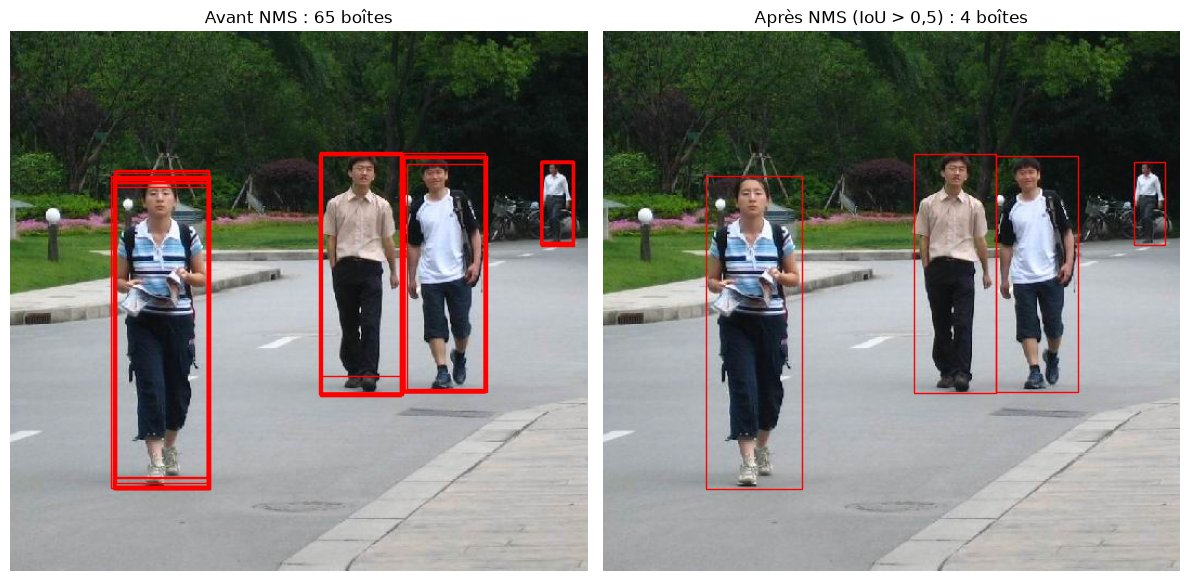

In [10]:
def nms_a_la_main(boites, scores, seuil_iou):
  """Indices des boîtes gardées, par score décroissant."""
  restantes = scores.argsort(descending=True)
  gardees = []
  while len(restantes) > 0:
    meilleure, autres = restantes[0], restantes[1:]
    gardees.append(int(meilleure))  # 1. la boîte de plus haut score
    ious = box_iou(boites[meilleure].unsqueeze(0), boites[autres])[0]
    restantes = autres[ious <= seuil_iou]  # 2. sans celles qui la recouvrent
  return torch.tensor(gardees)  # 3. jusqu'à ce qu'il n'en reste plus


est_personne = etiquettes_brutes == categories.index("person")
boites, scores = boites_brutes[est_personne], scores_bruts[est_personne]
gardees_main = nms_a_la_main(boites, scores, seuil_iou=0.5)
gardees = nms(boites, scores, iou_threshold=0.5)
print(f"Personnes : {len(boites)} boîtes → {len(gardees_main)} après la NMS")
print(f"Mêmes boîtes que torchvision : {torch.equal(gardees_main, gardees)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, titre, affichees in (
  (axes[0], f"Avant NMS : {len(boites)} boîtes", torch.arange(len(boites))),
  (axes[1], f"Après NMS (IoU > 0,5) : {len(gardees)} boîtes", gardees),
):
  affiche_image(ax, images[0])
  dessine_boites(ax, boites[affichees], epaisseur=1)
  ax.set_title(titre)
plt.tight_layout()
plt.show()

La NMS se fait classe par classe : une boîte de personne ne doit pas supprimer celle du sac à dos qu'elle recouvre. `batched_nms` applique `nms` séparément à chaque classe. Sur toutes les boîtes, elle retrouve les détections du modèle. Le seuil d'IoU règle le compromis : bas, il fusionne aussi des objets proches (une foule) ; haut, il laisse des doublons.

In [11]:
gardees = batched_nms(boites_brutes, scores_bruts, etiquettes_brutes, iou_threshold=0.5)
etiquettes_modele = pietons["labels"][pietons["scores"] >= seuil_score]
print(
  f"Après NMS : {sorted(categories[etiquette] for etiquette in etiquettes_brutes[gardees])}"
)
print(f"Le modèle : {sorted(categories[etiquette] for etiquette in etiquettes_modele)}")

for seuil_iou in (0.1, 0.3, 0.5, 0.7, 0.9):
  gardees = batched_nms(boites_brutes, scores_bruts, etiquettes_brutes, seuil_iou)
  print(f"Seuil d'IoU {seuil_iou} : {len(gardees)} boîtes gardées")

Après NMS : ['backpack', 'backpack', 'backpack', 'backpack', 'bicycle', 'bicycle', 'bicycle', 'person', 'person', 'person', 'person', 'sports ball']
Le modèle : ['backpack', 'backpack', 'backpack', 'backpack', 'bicycle', 'bicycle', 'bicycle', 'person', 'person', 'person', 'person', 'sports ball']
Seuil d'IoU 0.1 : 9 boîtes gardées
Seuil d'IoU 0.3 : 9 boîtes gardées
Seuil d'IoU 0.5 : 12 boîtes gardées
Seuil d'IoU 0.7 : 16 boîtes gardées
Seuil d'IoU 0.9 : 46 boîtes gardées


## Pour aller plus loin

- Les détecteurs à une étape de torchvision (`retinanet_resnet50_fpn_v2`, `fcos_resnet50_fpn`, `ssdlite320_mobilenet_v3_large`) ont la même interface : remplacez le modèle et comparez leurs boîtes et leur vitesse. Les détecteurs à base de transformers (DETR, RT-DETR) prédisent directement un ensemble d'objets, sans NMS.
- `torchmetrics.detection.MeanAveragePrecision` calcule la mAP à partir des détections et de la vérité terrain.
- Le [tutoriel de torchvision](https://docs.pytorch.org/tutorials/intermediate/torchvision_tutorial.html) affine ce même Faster R-CNN sur la base Penn-Fudan.